In [1]:
# ---- Student details (edit these, they appear in the PDF report) ----
STUDENT_NAME = "Zeel Barvaliya"
ENROLLMENT   = "23CS004"

## Cell 1 – Imports, seed, device

In [2]:
import copy, time, textwrap
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cpu")          # exam guideline: run on CPU
print("Torch:", torch.__version__, "| Device:", device)

Torch: 2.11.0+cpu | Device: cpu


## Cell 2 – Load MNIST (60,000 train / 10,000 test, pixels in [0,1])

In [3]:
tf = transforms.ToTensor()            # scales pixels to [0,1]
train_ds = datasets.MNIST("./data", train=True,  download=True, transform=tf)
test_ds  = datasets.MNIST("./data", train=False, download=True, transform=tf)

g = torch.Generator().manual_seed(42)
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, generator=g)
test_loader  = DataLoader(test_ds,  batch_size=1000, shuffle=False)
print("Train:", len(train_ds), "| Test:", len(test_ds), "| Image shape:", tuple(train_ds[0][0].shape))
DATASET_NAME = "MNIST"

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.48MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 145kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.37MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.0MB/s]


Train: 60000 | Test: 10000 | Image shape: (1, 28, 28)


## Task 1 – Baseline CNN (2 conv + 2 FC, Adam lr=0.001, batch 64, 2 epochs)

In [4]:
class DigitCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, 1)
        self.conv2 = nn.Conv2d(32, 64, 3, 1)
        self.fc1   = nn.Linear(9216, 128)
        self.fc2   = nn.Linear(128, 10)
    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

def accuracy(model, attack=None, eps=0.0):
    """Accuracy (%) on the full test set, optionally under an attack."""
    model.eval(); correct = 0
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        if attack is not None and eps > 0:
            x = attack(model, x, y, eps)
        with torch.no_grad():
            correct += (model(x).argmax(1) == y).sum().item()
    return 100.0 * correct / len(test_ds)

torch.manual_seed(42)
model = DigitCNN().to(device)
opt = torch.optim.Adam(model.parameters(), lr=0.001)

print("Training baseline CNN (2 epochs)...")
for epoch in range(2):
    model.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        loss = F.cross_entropy(model(x), y)
        loss.backward(); opt.step()
    print(f"  epoch {epoch+1} done | last batch loss = {loss.item():.4f}")
print("done.")

baseline = copy.deepcopy(model)       # keep the baseline safe for later comparison
clean_acc = accuracy(baseline)
print(f"Clean test accuracy : {clean_acc:.1f} %")

Training baseline CNN (2 epochs)...
  epoch 1 done | last batch loss = 0.0048
  epoch 2 done | last batch loss = 0.0129
done.
Clean test accuracy : 98.7 %


## Task 2 & 3 – FGSM and PGD attack implementation

In [5]:
def fgsm_attack(model, x, y, eps):
    """Fast Gradient Sign Method: x_adv = clip(x + eps * sign(grad_x loss))."""
    x_adv = x.clone().detach().requires_grad_(True)
    loss = F.cross_entropy(model(x_adv), y)
    grad = torch.autograd.grad(loss, x_adv)[0]
    return torch.clamp(x + eps * grad.sign(), 0, 1).detach()

def pgd_attack(model, x, y, eps, alpha=None, iters=10):
    """PGD (L-inf): random start, `iters` steps of size alpha=eps/4, project to eps-ball and [0,1]."""
    alpha = eps / 4 if alpha is None else alpha
    x_adv = torch.clamp(x + torch.empty_like(x).uniform_(-eps, eps), 0, 1).detach()
    for _ in range(iters):
        x_adv.requires_grad_(True)
        loss = F.cross_entropy(model(x_adv), y)
        grad = torch.autograd.grad(loss, x_adv)[0]
        x_adv = x_adv.detach() + alpha * grad.sign()
        x_adv = torch.min(torch.max(x_adv, x - eps), x + eps)   # project onto eps-ball
        x_adv = torch.clamp(x_adv, 0, 1).detach()               # valid pixel range
    return x_adv

EPS_LIST = [0.00, 0.05, 0.10, 0.20, 0.30]

torch.manual_seed(42)
fgsm_res, pgd_res = {}, {}
for e in EPS_LIST:
    if e == 0:
        fgsm_res[e] = pgd_res[e] = clean_acc
    else:
        fgsm_res[e] = accuracy(baseline, fgsm_attack, e)
        pgd_res[e]  = accuracy(baseline, pgd_attack,  e)

print(f"Clean test accuracy : {clean_acc:.1f} %\n")
print("EPSILON FGSM_ACC PGD_ACC")
print("-------------------------------")
for e in EPS_LIST:
    print(f" {e:.2f}   {fgsm_res[e]:5.1f} %  {pgd_res[e]:5.1f} %")
print("-------------------------------")
print(f"Attack success (eps=0.20): FGSM {100-fgsm_res[0.20]:.1f} %, PGD {100-pgd_res[0.20]:.1f} %")

Clean test accuracy : 98.7 %

EPSILON FGSM_ACC PGD_ACC
-------------------------------
 0.00    98.7 %   98.7 %
 0.05    95.7 %   95.1 %
 0.10    87.8 %   80.1 %
 0.20    44.0 %    0.9 %
 0.30     4.0 %    0.0 %
-------------------------------
Attack success (eps=0.20): FGSM 56.0 %, PGD 99.1 %


## Task 4 – 5 clean digits vs. their FGSM (ε = 0.20) versions with predicted labels

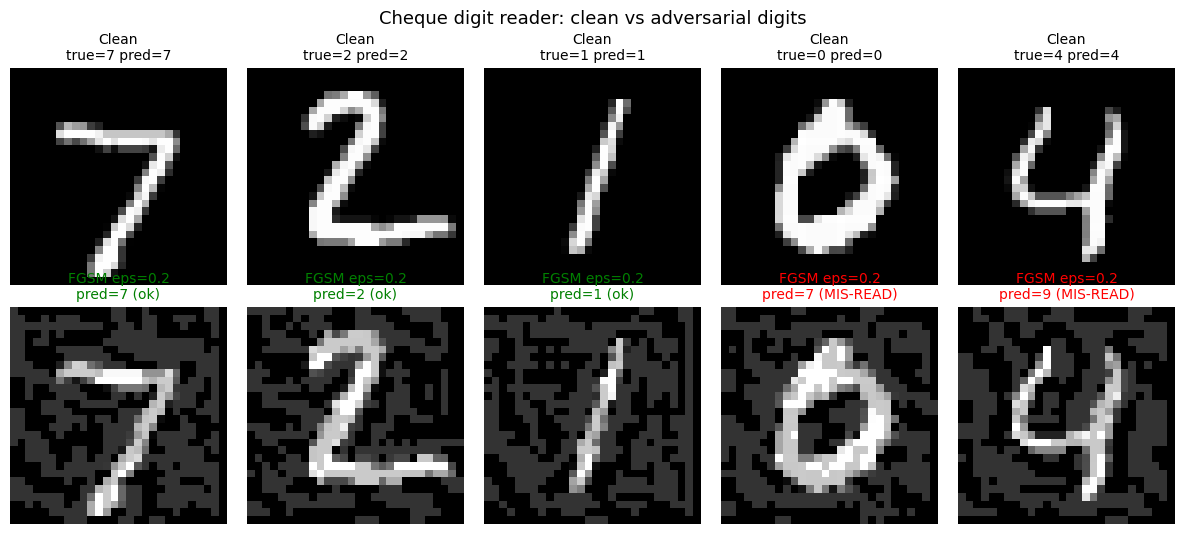

Mis-read digits saved : clean_vs_adversarial.png
  digit 0 was mis-read as 7
  digit 4 was mis-read as 9
2 out of 5 digits mis-read.


In [6]:
EPS_VIS = 0.20
baseline.eval()
X_all = torch.stack([test_ds[i][0] for i in range(200)])
Y_all = torch.tensor([test_ds[i][1] for i in range(200)])
with torch.no_grad():
    pred_clean_all = baseline(X_all).argmax(1)

# take the first 5 digits that the model reads correctly when clean
idx = (pred_clean_all == Y_all).nonzero().flatten()[:5]
x5, y5 = X_all[idx], Y_all[idx]
x5_adv = fgsm_attack(baseline, x5, y5, EPS_VIS)
with torch.no_grad():
    p_clean = baseline(x5).argmax(1)
    p_adv   = baseline(x5_adv).argmax(1)

fig, axes = plt.subplots(2, 5, figsize=(12, 5.4))
misread = []
for i in range(5):
    axes[0, i].imshow(x5[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[0, i].set_title(f"Clean\ntrue={y5[i].item()} pred={p_clean[i].item()}", fontsize=10)
    axes[1, i].imshow(x5_adv[i, 0], cmap="gray", vmin=0, vmax=1)
    wrong = p_adv[i].item() != y5[i].item()
    axes[1, i].set_title(f"FGSM eps={EPS_VIS}\npred={p_adv[i].item()} " + ("(MIS-READ)" if wrong else "(ok)"),
                         fontsize=10, color="red" if wrong else "green")
    if wrong: misread.append((y5[i].item(), p_adv[i].item()))
    axes[0, i].axis("off"); axes[1, i].axis("off")
plt.suptitle("Cheque digit reader: clean vs adversarial digits", fontsize=13)
plt.tight_layout()
plt.savefig("clean_vs_adversarial.png", dpi=150)
plt.show()

print("Mis-read digits saved : clean_vs_adversarial.png")
if misread:
    for t, p in misread: print(f"  digit {t} was mis-read as {p}")
else:
    print("  No digit mis-read among these 5.")
MISREAD_TEXT = ", ".join([f"{t} read as {p}" for t, p in misread]) if misread else "none of the 5 shown digits"
print(f"{len(misread)} out of 5 digits mis-read.")

## Task 5 – Adversarial training (fine-tune 2 epochs on 50:50 clean + FGSM ε=0.20)

In [7]:
adv_model = copy.deepcopy(baseline)
opt_adv = torch.optim.Adam(adv_model.parameters(), lr=0.001)
torch.manual_seed(42)

print("Adversarial training (2 epochs)... ")
for epoch in range(2):
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        adv_model.eval()                                    # craft attack against current model
        x_adv = fgsm_attack(adv_model, x, y, 0.20)
        adv_model.train()
        xb = torch.cat([x, x_adv]); yb = torch.cat([y, y])  # 50% clean : 50% adversarial
        opt_adv.zero_grad()
        loss = F.cross_entropy(adv_model(xb), yb)
        loss.backward(); opt_adv.step()
    print(f"  epoch {epoch+1} done | last batch loss = {loss.item():.4f}")
print("done.")

torch.manual_seed(42)
adv_clean = accuracy(adv_model)
adv_fgsm  = accuracy(adv_model, fgsm_attack, 0.20)
adv_pgd   = accuracy(adv_model, pgd_attack,  0.20)
print(f"Adversarially trained -> clean {adv_clean:.1f} % | FGSM(0.20) {adv_fgsm:.1f} % | PGD(0.20) {adv_pgd:.1f} %")

Adversarial training (2 epochs)... 
  epoch 1 done | last batch loss = 0.2776
  epoch 2 done | last batch loss = 0.0591
done.
Adversarially trained -> clean 99.2 % | FGSM(0.20) 95.2 % | PGD(0.20) 34.2 %


## Task 6 – Table (baseline vs adversarially trained) and accuracy-vs-ε plot

MODEL           CLEAN    FGSM(0.20)  PGD(0.20)
----------------------------------------------------
Baseline         98.7 %    44.0 %       0.9 %
Adversarially    99.2 %    95.2 %      34.2 %
trained
----------------------------------------------------
Clean accuracy change : +0.5 %
FGSM robustness gain : +51.2 %   PGD gain : +33.3 %


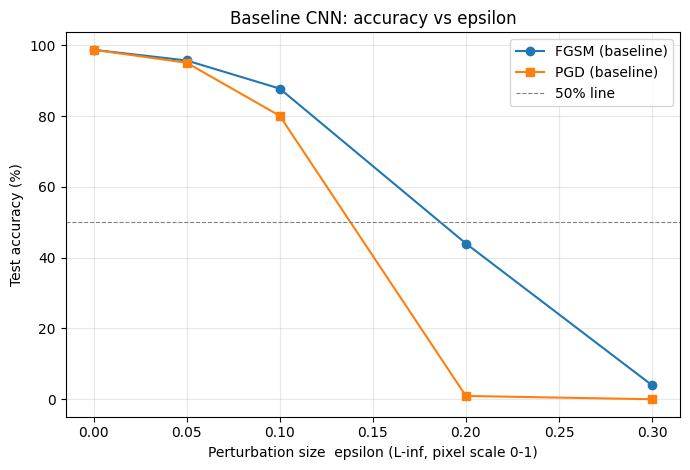

Plot saved : accuracy_vs_epsilon.png


In [8]:
b_c, b_f, b_p = clean_acc, fgsm_res[0.20], pgd_res[0.20]

print("MODEL           CLEAN    FGSM(0.20)  PGD(0.20)")
print("----------------------------------------------------")
print(f"Baseline        {b_c:5.1f} %   {b_f:5.1f} %     {b_p:5.1f} %")
print(f"Adversarially   {adv_clean:5.1f} %   {adv_fgsm:5.1f} %     {adv_pgd:5.1f} %")
print("trained")
print("----------------------------------------------------")
print(f"Clean accuracy change : {adv_clean-b_c:+.1f} %")
print(f"FGSM robustness gain : {adv_fgsm-b_f:+.1f} %   PGD gain : {adv_pgd-b_p:+.1f} %")

plt.figure(figsize=(7, 4.8))
plt.plot(EPS_LIST, [fgsm_res[e] for e in EPS_LIST], "o-", label="FGSM (baseline)")
plt.plot(EPS_LIST, [pgd_res[e]  for e in EPS_LIST], "s-", label="PGD (baseline)")
plt.axhline(50, color="gray", ls="--", lw=0.8, label="50% line")
plt.xlabel("Perturbation size  epsilon (L-inf, pixel scale 0-1)")
plt.ylabel("Test accuracy (%)")
plt.title("Baseline CNN: accuracy vs epsilon")
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout()
plt.savefig("accuracy_vs_epsilon.png", dpi=150)
plt.show()
print("Plot saved : accuracy_vs_epsilon.png")

## Build the PDF report (aim, algorithm, program summary, output, conclusion + answers to Q1–Q4 from YOUR results)

In [9]:
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.image as mpimg

# ---------- dynamic answers ----------
below50 = [e for e in EPS_LIST if e > 0 and fgsm_res[e] < 50]
eps50 = below50[0] if below50 else None
fgsm_lines = "; ".join([f"eps={e:.2f}: {fgsm_res[e]:.1f}%" for e in EPS_LIST])

Q1 = (f"Clean accuracy = {clean_acc:.1f}%. FGSM accuracy -> {fgsm_lines}. "
      + (f"Accuracy first falls below 50% at eps = {eps50:.2f} ({fgsm_res[eps50]:.1f}%). " if eps50
         else "Accuracy did not fall below 50% for the tested eps values. ")
      + "A tiny perturbation works because the network is highly non-linear yet behaves almost linearly in high "
        "dimensions: a change of size eps on each of the 784 pixels, all aligned with the sign of the loss gradient, "
        "adds up (eps x L1-norm of the gradient) to a large change in the logits and crosses the decision boundary, "
        "although every single pixel changes very little and a human still sees the same digit.")

stronger = "PGD" if pgd_res[0.20] < fgsm_res[0.20] else "FGSM"
cmp_lines = "; ".join([f"eps={e:.2f}: FGSM {fgsm_res[e]:.1f}% vs PGD {pgd_res[e]:.1f}%" for e in EPS_LIST if e > 0])
Q2 = (f"{cmp_lines}. {stronger} is the stronger attack (lower accuracy at every eps; at eps=0.20 the attack success is "
      f"FGSM {100-fgsm_res[0.20]:.1f}% vs PGD {100-pgd_res[0.20]:.1f}%). FGSM takes only one gradient step, which is a "
      "linear approximation of the loss. PGD is an iterative version: it takes 10 small steps, re-computes the gradient "
      "each time, starts from a random point and projects back into the eps-ball, so it follows the curved loss surface "
      "and finds much better adversarial examples inside the same eps budget.")

Q3 = (f"In the clean-vs-adversarial figure (FGSM eps=0.20) the mis-read digits were: {MISREAD_TEXT}. "
      f"Adversarial training changed accuracy as follows: clean {b_c:.1f}% -> {adv_clean:.1f}% ({adv_clean-b_c:+.1f}%), "
      f"FGSM(0.20) {b_f:.1f}% -> {adv_fgsm:.1f}% ({adv_fgsm-b_f:+.1f}%), "
      f"PGD(0.20) {b_p:.1f}% -> {adv_pgd:.1f}% ({adv_pgd-b_p:+.1f}%). "
      "So robustness improved a lot while clean accuracy stayed about the same. PGD accuracy remains lower than FGSM "
      "accuracy because the model was trained only against single-step FGSM examples.")

Q4 = ("Epsilon is the maximum L-infinity perturbation allowed for every pixel (on a 0-1 scale), i.e. the attacker's "
      "'budget' or how visible the tampering is. In the plot accuracy drops as eps grows, and PGD drops faster than "
      "FGSM, so the digit reader is only reliable for very small eps. Two further defences: (1) PGD-based (multi-step) "
      "adversarial training / ensembles of differently trained models, so the model is robust to stronger attacks than "
      "FGSM; (2) input pre-processing and detection - denoising / JPEG compression / binarisation of cheque images with "
      "adversarial-example detection, plus a human-in-the-loop check (compare the digit reading with the written "
      "amount in words, confidence thresholds, manual review for high-value cheques).")

# ---------- helpers ----------
def text_page(pdf, title, paragraphs, mono=False):
    fig = plt.figure(figsize=(8.27, 11.69)); ax = fig.add_axes([0.07, 0.04, 0.86, 0.9]); ax.axis("off")
    ax.text(0, 1, title, fontsize=15, fontweight="bold", va="top")
    y = 0.95
    for p in paragraphs:
        wrapped = p if mono else textwrap.fill(p, 95)
        ax.text(0, y, wrapped, fontsize=9 if mono else 10, va="top", family="monospace" if mono else None)
        y -= 0.027 * (wrapped.count("\n") + 1) + 0.02
    pdf.savefig(fig); plt.close(fig)

def image_page(pdf, title, path):
    fig = plt.figure(figsize=(8.27, 11.69)); ax = fig.add_axes([0.05, 0.2, 0.9, 0.65]); ax.axis("off")
    ax.imshow(mpimg.imread(path)); fig.suptitle(title, fontsize=13, y=0.9)
    pdf.savefig(fig); plt.close(fig)

table_a = ["EPSILON   FGSM_ACC   PGD_ACC", "-----------------------------"] + \
          [f" {e:.2f}     {fgsm_res[e]:5.1f} %   {pgd_res[e]:5.1f} %" for e in EPS_LIST]
table_b = ["MODEL                 CLEAN     FGSM(0.20)   PGD(0.20)",
           "------------------------------------------------------",
           f"Baseline              {b_c:5.1f} %    {b_f:5.1f} %      {b_p:5.1f} %",
           f"Adversarially trained {adv_clean:5.1f} %    {adv_fgsm:5.1f} %      {adv_pgd:5.1f} %",
           "------------------------------------------------------",
           f"Clean accuracy change : {adv_clean-b_c:+.1f} %",
           f"FGSM robustness gain  : {adv_fgsm-b_f:+.1f} %    PGD gain : {adv_pgd-b_p:+.1f} %"]

with PdfPages("RSA_Practical_Report.pdf") as pdf:
    text_page(pdf, "Adversarial Attacks on an Automated Cheque-Amount Digit Reader", [
        f"Name: {STUDENT_NAME}      Enrollment: {ENROLLMENT}",
        "Subject: Responsible and Safe AI (AIML4001) - External Practical, Set A     Date: 25/11/2026",
        f"Dataset used: {DATASET_NAME} (60,000 train / 10,000 test, 28x28 grey-scale)   |   Tools: Python 3, PyTorch, "
        "Torchvision, NumPy, Matplotlib   |   Seed 42, CPU",
        "AIM: To measure how vulnerable a CNN digit reader (used for cheque-amount reading) is to FGSM and PGD "
        "adversarial evasion attacks, and to harden it using adversarial training.",
        "ALGORITHM:\n1. Load MNIST, pixels in [0,1].\n2. Train baseline CNN (2 conv + 2 FC, Adam lr=0.001, batch 64, 2 epochs); "
        "report clean accuracy.\n3. FGSM: x_adv = clip(x + eps*sign(grad_x L(x,y)), 0, 1) for eps = 0.05, 0.10, 0.20, 0.30.\n"
        "4. PGD (L-inf): random start in [-eps, eps]; repeat 10 times: x = x + alpha*sign(grad), alpha = eps/4, project to "
        "the eps-ball and [0,1].\n5. Display 5 clean digits and their FGSM (eps=0.20) versions with predicted labels.\n"
        "6. Adversarial training: fine-tune 2 epochs on 50:50 clean + FGSM(eps=0.20) images; re-evaluate clean, FGSM, "
        "PGD at eps=0.20.\n7. Plot accuracy vs eps and tabulate baseline vs adversarially trained results.",
        "PROGRAM: See the submitted notebook / .py file (RSA_Practical_SetA.ipynb).",
    ])
    text_page(pdf, "Output", [
        f"Training baseline CNN (2 epochs)... done.\nClean test accuracy : {clean_acc:.1f} %",
        "Part A: Baseline model under attack", "\n".join(table_a),
        f"Attack success (eps=0.20): FGSM {100-fgsm_res[0.20]:.1f} %, PGD {100-pgd_res[0.20]:.1f} %",
        "Part B: Adversarial training (defence)", "\n".join(table_b),
    ], mono=True)
    image_page(pdf, "Clean vs adversarial digits (FGSM eps=0.20)", "clean_vs_adversarial.png")
    image_page(pdf, "Accuracy vs epsilon (baseline)", "accuracy_vs_epsilon.png")
    text_page(pdf, "Conclusion and Technical Questions", [
        f"CONCLUSION: The baseline CNN reaches {clean_acc:.1f}% clean accuracy but collapses under small, almost invisible "
        f"perturbations (FGSM {fgsm_res[0.20]:.1f}%, PGD {pgd_res[0.20]:.1f}% at eps=0.20). Adversarial training raised "
        f"robust accuracy to FGSM {adv_fgsm:.1f}% and PGD {adv_pgd:.1f}% while clean accuracy stayed at {adv_clean:.1f}%. "
        "Hence adversarial training should be combined with other defences before the cheque system goes live.",
        "Q1. " + Q1, "Q2. " + Q2, "Q3. " + Q3, "Q4. " + Q4,
    ])
print("PDF saved : RSA_Practical_Report.pdf")
print("\nQ1.", Q1, "\n\nQ2.", Q2, "\n\nQ3.", Q3, "\n\nQ4.", Q4)

PDF saved : RSA_Practical_Report.pdf

Q1. Clean accuracy = 98.7%. FGSM accuracy -> eps=0.00: 98.7%; eps=0.05: 95.7%; eps=0.10: 87.8%; eps=0.20: 44.0%; eps=0.30: 4.0%. Accuracy first falls below 50% at eps = 0.20 (44.0%). A tiny perturbation works because the network is highly non-linear yet behaves almost linearly in high dimensions: a change of size eps on each of the 784 pixels, all aligned with the sign of the loss gradient, adds up (eps x L1-norm of the gradient) to a large change in the logits and crosses the decision boundary, although every single pixel changes very little and a human still sees the same digit. 

Q2. eps=0.05: FGSM 95.7% vs PGD 95.1%; eps=0.10: FGSM 87.8% vs PGD 80.1%; eps=0.20: FGSM 44.0% vs PGD 0.9%; eps=0.30: FGSM 4.0% vs PGD 0.0%. PGD is the stronger attack (lower accuracy at every eps; at eps=0.20 the attack success is FGSM 56.0% vs PGD 99.1%). FGSM takes only one gradient step, which is a linear approximation of the loss. PGD is an iterative version: it ta

## Save the notebook outputs (downloads PDF + plots; also keeps them in the Colab folder)

In [11]:
import shutil
shutil.make_archive("RSA_submission", "zip", ".", None)  # zips the whole folder
print("Created RSA_submission.zip - download it from the left file panel")

Created RSA_submission.zip - download it from the left file panel


In [12]:
import zipfile
with zipfile.ZipFile("RSA_submission.zip", "w") as z:
    for f in ["RSA_Practical_Report.pdf", "clean_vs_adversarial.png", "accuracy_vs_epsilon.png"]:
        z.write(f)
print("Created RSA_submission.zip")

Created RSA_submission.zip
